# Jacobian-lens layer-by-token preview with PrivacyGuard
For questions, reach out to Matthew Grange

This tutorial loads a `privacyguard.jlens_preview/v1` receipt, summarizes it with the optional, experimental
`JacobianLensPreviewNode`, and renders a self-contained interactive layer-by-token viewer.

The example is the prompt `The number of legs on the animal that spins webs is`. The model's own output is the
reference: a Jacobian lens (J-lens) and an ordinary logit lens read out ranked vocabulary tokens at every
(layer, token position) cell, and the viewer tracks the ranks of `spider`, `ant`, `8` and `6`.

What this analysis does **not** claim: it says nothing about model intent, a global workspace, consciousness or
privacy efficacy. J-lens layers are candidate sites, not validated workspace bands. A readout is not a causal
result; the spider-to-ant intervention and its controls are reported separately, including negative results.

## Environment set-up

Install PrivacyGuard from a clone of the repository. The preview needs only the base dependencies
(`torch`, `pandas`, `matplotlib`); it loads no model and makes no network call.

In [1]:
# From the repository root:
# !pip install -e .

In [2]:
import gzip
import json
import os

import matplotlib.pyplot as plt
import pandas as pd

from privacy_guard.analysis.jacobian_lens.preview_analysis_input import JacobianLensPreviewInput
from privacy_guard.analysis.jacobian_lens.preview_analysis_node import JacobianLensPreviewNode
from privacy_guard.analysis.jacobian_lens.preview_schema import JLensPreviewReceipt
from privacy_guard.analysis.jacobian_lens.preview_viewer import HTML_FILENAME, write_preview_bundle

## Load and validate the receipts

A receipt file (optionally gzip-compressed) holds a JSON list with one receipt per prompt. Loading validates the schema,
the pinned identity fields, rank consistency, the receipt hash, and rejects any activation, residual, logit array
or weight payload. A receipt whose `run_kind` is not `real_model` is a fixture and is labeled as such everywhere.

In [3]:
RECEIPTS_PATH = os.environ.get("JLENS_RECEIPTS_PATH", "data/jacobian_lens/jlens_preview_receipts.json.gz")

opener = gzip.open if RECEIPTS_PATH.endswith(".gz") else open
with opener(RECEIPTS_PATH, "rt", encoding="utf-8") as f:
    receipts = [JLensPreviewReceipt.from_dict(r) for r in json.load(f)]

for r in receipts:
    print(f"{r.prompt.label}: {r.prompt.text!r}")
    print(f"  {r.run_kind} / {r.model_role}: {r.model_identity['repo_id']} @ {r.model_identity['revision_sha']} ({r.model_identity['dtype']})")
    print(f"  lens: {None if r.lens is None else r.lens['lens_id']} (n_prompts={None if r.lens is None else r.lens.get('n_prompts')})")
    print(f"  scores: {r.score_definition}")
    print(f"  receipt sha256: {r.receipt_sha256}")


blog_literal: 'The number of legs on the animal that spins webs is.'
  real_model / glimmer_target: meta-models/Muse-Glimmer-30B @ 1297fd7dfeac4598948a5d15886968435c81c2b7 (bfloat16)
  lens: lens_merged.pt (n_prompts=32)
  scores: native head evaluated in float32: cap * tanh(output_multiplier * lm_head(final_norm(h)) / cap), cap = final_logit_softcapping
  receipt sha256: 0c224601d03db71631039ee2e81a48ec38dedaf7b8f173f95bc16d02316e3234
blog_no_period: 'The number of legs on the animal that spins webs is'
  real_model / glimmer_target: meta-models/Muse-Glimmer-30B @ 1297fd7dfeac4598948a5d15886968435c81c2b7 (bfloat16)
  lens: lens_merged.pt (n_prompts=32)
  scores: native head evaluated in float32: cap * tanh(output_multiplier * lm_head(final_norm(h)) / cap), cap = final_logit_softcapping
  receipt sha256: 2f6c41d7013b8f19e471c050e7fc2d954dd50ad77f11284dd684c9c72b5179ad
upstream_probe_swap: 'Fact: The number of legs on the animal that spins webs is '
  real_model / glimmer_target: meta-m

## Summarize with the analysis node

`head_consistency` checks that the final-layer logit lens at the last prompt position reproduces the model's
actual next-token scores. `answer_margins` compares the best `6` score with the best `8` score at the next token,
for the actual output and for each intervention or control run.

In [4]:
HEAD_SCORE_TOLERANCE = 0.125  # one BF16 step at |score| in [16, 32)
summaries = [
    JacobianLensPreviewNode(JacobianLensPreviewInput(r), head_score_tolerance=HEAD_SCORE_TOLERANCE).compute_outputs()
    for r in receipts
]
for receipt, summary in zip(receipts, summaries):
    print(receipt.prompt.label or receipt.prompt.text)
    print("  labels:", *summary["labels"], sep="\n    ")
    print("  actual next token:", summary["actual_next_token"], "greedy:", repr(summary["actual_greedy_text"]))
    print("  head consistency:", summary["head_consistency"])
    margins = pd.DataFrame(summary["answer_margins"])
    if not margins.empty:
        columns = ["name", "kind", "primary", "margin", "preferred_rank", "reference_rank"]
        print(margins[columns].round(3).to_string(index=False))

blog_literal
  labels:
    J-lens layers are candidate sites, not validated workspace bands
    predeclared primary intervention arm: clamp_band_s1; other intervention arms are exploratory
  actual next token: {'token_id': 352, 'text': ' A'} greedy: ' A. 6 B. 8'
  head consistency: {'checked': True, 'top1_match': True, 'max_abs_score_diff': 0.054999999999999716, 'tolerance': 0.125, 'consistent': True}
                            name                   kind  primary  margin  preferred_rank  reference_rank
                   actual_output                 actual    False  -1.187             110              44
                        baseline               baseline    False  -1.187             110              44
                  noop_zero_edit                   noop    False  -1.187             110              44
                 clamp_band_s0.5           intervention    False  -0.625              95              62
unrelated_matched_norm_band_s0.5 matched_norm_unrelated    False  -0.5

## Rank curves at the last prompt position

Each line is the best full-vocabulary rank over a concept's tracked token variants (for example `" spider"` and
`" spiders"`), for the concepts spider, ant, 8 and 6. Solid lines are the J-lens, dashed lines the logit lens. The
viewer below shows every tracked concept, layer and position.

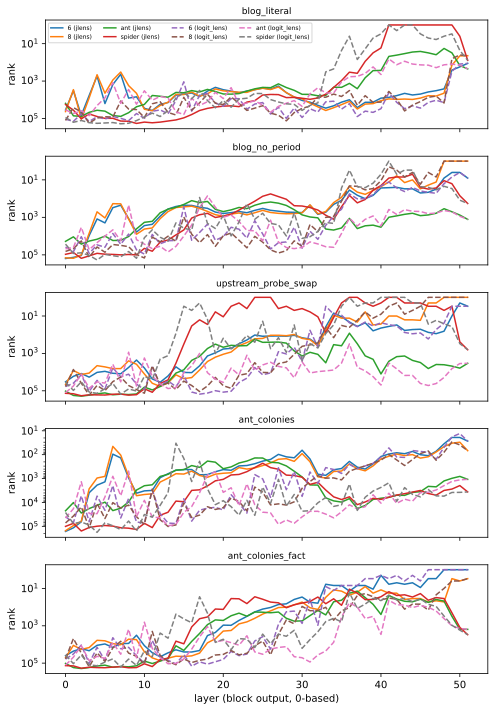

In [5]:
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("svg")  # small, text-based figure in the saved notebook
plt.rcParams.update({"svg.fonttype": "none", "svg.hashsalt": "jlens-preview"})
CONCEPTS = ("spider", "ant", "8", "6")
fig, axes = plt.subplots(len(receipts), 1, figsize=(7, 2.0 * len(receipts)), sharex=True)
for ax, receipt, summary in zip(axes, receipts, summaries):
    last = len(receipt.prompt.token_ids) - 1
    for curve in summary["rank_curves"]:
        if curve["position"] != last or curve["concept"] not in CONCEPTS:
            continue
        points = [(layer, rank) for layer, rank in zip(curve["layers"], curve["best_rank"]) if rank is not None]
        if points:
            ax.plot(*zip(*points), linestyle="-" if curve["method"] == "jlens" else "--", label=f"{curve['concept']} ({curve['method']})")
    ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set_ylabel("rank")
    ax.set_title(receipt.prompt.label, fontsize=9)
axes[0].legend(fontsize=6, ncol=4)
axes[-1].set_xlabel("layer (block output, 0-based)")
fig.tight_layout()
plt.show()

## Tracked-token ranks as a table

`JacobianLensPreviewInput.tracked_ranks` is a long table with one row per (method, layer, position, tracked token);
here it is pivoted for the reference prompt at its last position.

In [6]:
reference = next((r for r in receipts if r.prompt.label == "upstream_probe_swap"), receipts[0])
table = JacobianLensPreviewInput(reference).tracked_ranks
last = len(reference.prompt.token_ids) - 1
print(reference.prompt.label, "final position", last, repr(reference.prompt.token_texts[last]))
pivot = table[(table["source"] == "receipt") & (table["position"] == last)].pivot_table(
    index="layer", columns=["method", "concept"], values="rank", aggfunc="min"
)
print(pivot[["jlens", "logit_lens"]].loc[:, (slice(None), list(CONCEPTS))].to_string())

upstream_probe_swap final position 14 ' '
method    jlens logit_lens   jlens logit_lens  jlens logit_lens  jlens logit_lens
concept  spider     spider     ant        ant      8          8      6          6
layer                                                                            
0        136654      35305  104603     126955  46938      59072  33333      59609
1        144508      95467  177733      55505   8213       7300  16865      39276
2        184586      33032  194412      12927  13481      39143  11942      13937
3        164086     116767  172248      73163  11313     172981  18668     107843
4        166610     137092  145061      33481   4533      51885  10379      27884
5        169030      78240  130118      38821   5276      98314   9115      80209
6        153428      40967  164520       3804   6535      32425  11595       5952
7        150111     151818  152201      33271   6506      18417  12301      17761
8        171473      79711  159160        863   2506    

## Interactive layer-by-token viewer

The next cell writes the viewer next to this notebook (it is not stored in the repository: the page embeds every
receipt, about 15 MB here). The viewer is one HTML file with inlined data, CSS and JavaScript and a Content-Security-Policy that blocks all
network requests. Click a cell for the ranked vocabulary (raw token IDs, decoded text, scores and full-vocabulary
ranks), J-lens next to logit lens next to the actual output, tracked-token ranks and rank curves. The optional
word-only display filter is labeled and never changes the reported ranks.

In [7]:
output_dir = "jlens_preview_output"
digests = write_preview_bundle(receipts, output_dir, head_score_tolerance=HEAD_SCORE_TOLERANCE)
for name, digest in sorted(digests.items()):
    print(digest, name)
print(f"Open {os.path.join(output_dir, HTML_FILENAME)} in a browser; it needs no network access.")


89dcc2ab1f561cb0c2e3b90073d7b42e7e89661cceb2130e8aac04269909d116 jlens_preview.html
b4c93bd6b72d1e5cd614b2d042e38208a51fe6168917b69e971e8b75d0caa456 jlens_preview_receipts.json
4a5b6e2c31d7d8a83c88a79df33d019f2316a6b15f4a5294f4ac9c99e13b52a5 jlens_preview_summaries.json
Open jlens_preview_output/jlens_preview.html in a browser; it needs no network access.


## Regenerating the receipts

The bundled receipts come from the public `meta-models/Muse-Glimmer-30B` main BF16 checkpoint at the revision pinned in
each receipt's `model_identity` (its shard and tokenizer SHA-256 values are verified before loading). Regenerating them
needs one GPU with about 80 GB of memory and the checkpoint downloaded locally; the command each receipt was produced
with is recorded, with local paths replaced by placeholders, in its `code.run_command`:

The bundled `data/jacobian_lens/jlens_preview_receipts.json.gz` was trimmed from a receipts file with SHA-256
`21ccdc1bcd70fd447dc1a3dabb7aa4b079b89273291d34410a474e5969cd3b89` (five prompts, top-10 lists, all intervention
readouts).


In [8]:
for receipt in receipts:
    print(receipt.prompt.label, "|", receipt.code.get("run_command"))


blog_literal | python -m privacy_guard.analysis.jacobian_lens.glimmer_preview_pipeline run --causal --checkpoint-dir CKPT --checkpoint-every 2 --code-rev ec397a6f404c --device cuda --dim-batch 8 --fit-manifest OUT/FIT_MANIFEST.json --followups --heldout 8 --heldout-start 200 --lens PRIVATE/LENS.pt --max-new-tokens 8 --max-seq-len 128 --n-prompts 100 --num-shards 1 --out-dir OUT --private-dir PRIVATE --prompts blog_literal blog_no_period upstream_probe_swap ant_colonies ant_colonies_fact --seed 0 --shard 0 --shard-lenses --shard-manifests --top-k 10
blog_no_period | python -m privacy_guard.analysis.jacobian_lens.glimmer_preview_pipeline run --causal --checkpoint-dir CKPT --checkpoint-every 2 --code-rev ec397a6f404c --device cuda --dim-batch 8 --fit-manifest OUT/FIT_MANIFEST.json --followups --heldout 8 --heldout-start 200 --lens PRIVATE/LENS.pt --max-new-tokens 8 --max-seq-len 128 --n-prompts 100 --num-shards 1 --out-dir OUT --private-dir PRIVATE --prompts blog_literal blog_no_period up

Render a bundle from any receipts file without a GPU (the actual output comes from the native BF16 forward pass while cell
scores use the head in float32, so the final-layer consistency check allows one BF16 step, 0.125):

```
python -m privacy_guard.analysis.jacobian_lens.preview_render_main \
    --receipts data/jacobian_lens/jlens_preview_receipts.json.gz --out-dir jlens_preview_output --head-score-tolerance 0.125
```

The bundled file is trimmed for size (shorter top lists, rounded scores, patched-pass readouts kept for the primary arm
only); `display.trimmed` in each receipt records the SHA-256 of the full receipt it came from.

## Attribution

- Jacobian lens method and estimator: Anthropic, `jacobian-lens` reference implementation at commit
  `581d398613e5602a5af361e1c34d3a92ea82ba8e` (Apache License 2.0).
- Model: `meta-models/Muse-Glimmer-30B` main BF16 checkpoint (model card license Apache-2.0); the exact revision
  and file hashes are in each receipt's `model_identity`.